# 1. Import & Data Loading
Welcome to the Titanic Machine Learning project! In this initial section, we load the essential data science libraries and import our training and testing datasets from the Kaggle directory.

In [1]:
# Import essential data science and manipulation libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load training and testing datasets from the local data directory
train_pd = pd.read_csv("data/train.csv")
test_pd = pd.read_csv("data/test.csv")

# Preview the first few rows of the training dataset using .head() for a cleaner output
display(train_pd.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# 2. Combining Datasets
To ensure consistent feature engineering, data cleaning, and missing value imputation across both sets, we temporarily separate the target variable (`Survived`) from the training data and concatenate the training and testing datasets.

In [2]:
# Extract the target variable ('Survived') from the training dataset
survived = train_pd['Survived']

# Drop 'Survived' from train_pd so columns match the test set for concatenation
train_pd = train_pd.drop(['Survived'], axis=1)

# Save passenger IDs for later submission use, then combine train and test sets
train_idx = train_pd['PassengerId']
test_idx = test_pd['PassengerId']

combined_pd = pd.concat([train_pd, test_pd]).reset_index(drop=True)

# Preview the combined dataset
display(combined_pd.head())

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# 3. Missing Values Analysis
Before imputing missing data, we inspect our combined dataset to identify exactly how many null values exist across each feature column

In [3]:
# Check and display the total count of missing (null) values per column
print("NULL VALUES:")
print(combined_pd.isnull().sum())

NULL VALUES:
PassengerId       0
Pclass            0
Name              0
Sex               0
Age             263
SibSp             0
Parch             0
Ticket            0
Fare              1
Cabin          1014
Embarked          2
dtype: int64


# 4. Age Data Analysis & Imputation
We notice that passenger age correlates strongly with passenger class (e.g., first-class passengers tend to be older). Instead of filling missing ages with the overall global median, we impute them using the median age of their respective passenger class (`Pclass`)[cite: 1].

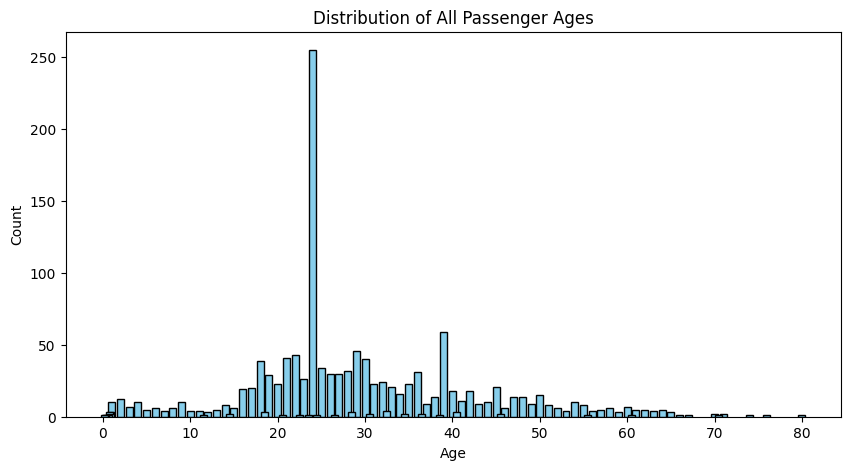

In [13]:
# Visualize the distribution of ages across the dataset
age_counts = combined_pd['Age'].value_counts()
ages = age_counts.index.values

plt.figure(figsize=(10, 5))
plt.bar(ages, age_counts, color='skyblue', edgecolor='black')
plt.title("Distribution of All Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

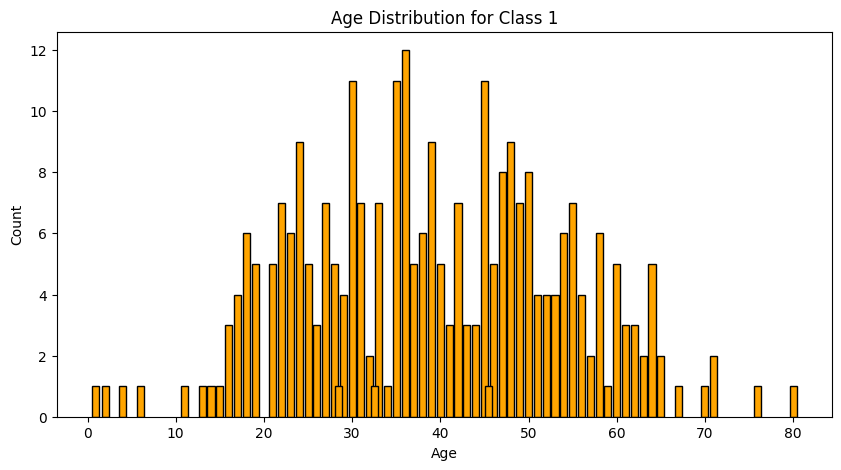

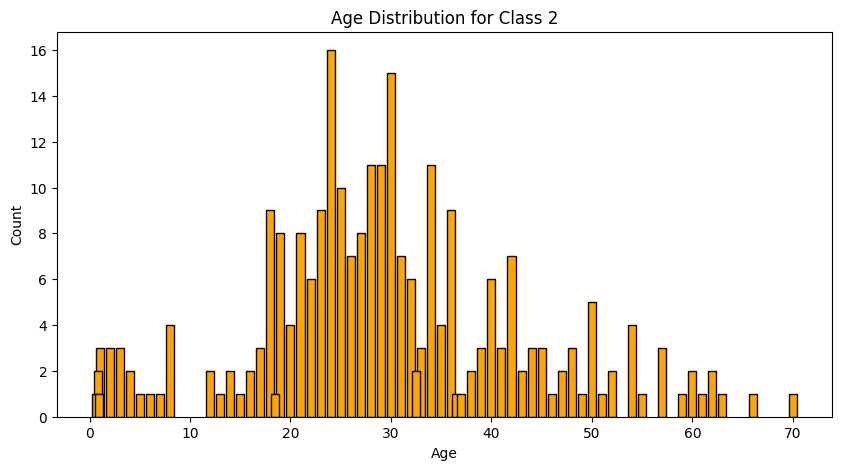

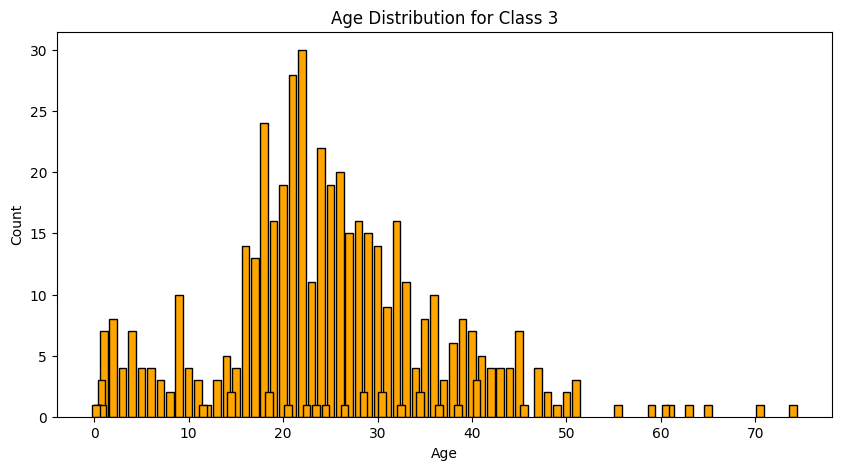

Median Ages by Class:
         Age
Pclass      
1       39.0
2       29.0
3       24.0


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Visualize age distributions broken down by Passenger Class
class_age = combined_pd[['Pclass', 'Age']]

for pclass in range(1, 4):
    plt.figure(figsize=(10, 5))
    plt.title(f'Age Distribution for Class {pclass}')
    class_data = class_age[class_age['Pclass'] == pclass]['Age'].value_counts()
    plt.bar(class_data.index.values, class_data.values, color='orange', edgecolor='black')
    plt.xlabel("Age")
    plt.ylabel("Count")
    plt.show()

# Calculate the median age for each passenger class
age_medians = class_age.groupby('Pclass').median()
print("Median Ages by Class:")
print(age_medians)        

# Fill missing age values using the median of the corresponding passenger class
for i in range(3):
    missing_indices = np.where((combined_pd['Pclass'] == i + 1) & (combined_pd['Age'].isnull()))[0]
    combined_pd.loc[missing_indices, 'Age'] = age_medians.values[i][0]

# Preview dataset after age imputation
display(combined_pd.head())


# 5. Missing Fare Imputation
We identify passengers with missing fare data and fill them using the median fare of similar passengers (those in the same passenger class and boarding port).

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1043,1044,3,"Storey, Mr. Thomas",male,60.5,0,0,3701,NaN,NaN,S


Calculated Median Fare: 8.05


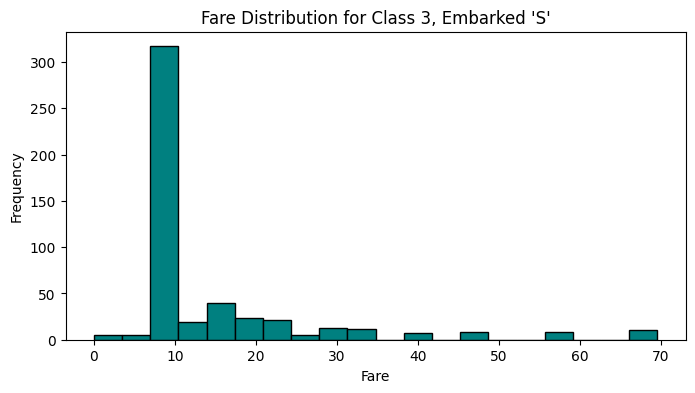

In [6]:
# Display the row with the missing Fare value
display(combined_pd[combined_pd['Fare'].isnull()])

# Find similar passengers (3rd class, embarked from 'S') and calculate their median fare
sim_fares = combined_pd[(combined_pd['Pclass'] == 3) & (combined_pd['Embarked'] == 'S')]['Fare']
print('Calculated Median Fare:', sim_fares.median())

# Plot the fare distribution for context
plt.figure(figsize=(8, 4))
plt.hist(sim_fares.dropna(), bins=20, color='teal', edgecolor='black')
plt.title("Fare Distribution for Class 3, Embarked 'S'")
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.show()

# Fill the missing Fare value with the calculated median
combined_pd['Fare'] = combined_pd['Fare'].fillna(sim_fares.median())

# 6. Missing Embarked Imputation
We check passengers with missing port of embarkation (`Embarked`) values and deduce their location based on class and ticket fare.

In [7]:
# Display passengers with missing Embarked values
display(combined_pd[combined_pd['Embarked'].isnull()])

# Analyze embarkation ports for first-class passengers who paid a similar fare (~80)
sim_emb = combined_pd[(combined_pd['Pclass'] == 1) & (combined_pd['Fare'] >= 75) & (combined_pd['Fare'] <= 85)]['Embarked']
print("Embarkation counts for similar fares:")
print(sim_emb.value_counts())

# Fill missing Embarked values with the most frequent port ('C')
combined_pd['Embarked'] = combined_pd['Embarked'].fillna('C')

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


Embarkation counts for similar fares:
Embarked
C    25
S    18
Name: count, dtype: int64


# 7. Cabin Feature Cleaning & Imputation
Since a large majority of cabin data is missing, we fill missing values with a placeholder category `'M'` (for Missing). Then, we extract the first letter of each cabin to represent the ship deck.

In [8]:
# Fill missing Cabin values with 'M' (Missing)
combined_pd['Cabin'] = combined_pd['Cabin'].fillna('M')

# Extract the first letter of the cabin to represent the deck level
combined_pd['Cabin'] = combined_pd['Cabin'].str[0]
print("Cabin Deck Value Counts:")
print(combined_pd['Cabin'].value_counts())

# Replace the rare/unknown 'T' cabin with 'M'
rare_indices = np.where(combined_pd['Cabin'] == 'T')[0]
combined_pd.loc[rare_indices, 'Cabin'] = 'M'

# Verify updated cabin value counts
print("\nUpdated Cabin Deck Value Counts:")
print(combined_pd['Cabin'].value_counts())

Cabin Deck Value Counts:
Cabin
M    1014
C      94
B      65
D      46
E      41
A      22
F      21
G       5
T       1
Name: count, dtype: int64

Updated Cabin Deck Value Counts:
Cabin
M    1015
C      94
B      65
D      46
E      41
A      22
F      21
G       5
Name: count, dtype: int64


# 8. Feature Extraction & Name Processing
We verify that no null values remain in the dataset. Then, we parse passenger names to extract titles (e.g., Mr., Miss, Mrs) and last names as potential predictive features.

In [9]:
# Verify that no missing values remain in the dataset
print("Remaining Null Values:")
print(combined_pd.isnull().sum())

# Check unique value counts for each feature
print("\nUnique Value Counts:")
print(combined_pd.nunique())

Remaining Null Values:
PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

Unique Value Counts:
PassengerId    1309
Pclass            3
Name           1307
Sex               2
Age              98
SibSp             7
Parch             8
Ticket          929
Fare            281
Cabin             8
Embarked          3
dtype: int64


In [10]:
# Extract titles and last names from the 'Name' column
names = combined_pd['Name']
last_names, titles, first_names = [], [], []

for name in names:
    if ', ' not in name:
        last_names.append('')
    else:
        last, remaining = name.split(', ', 1)
        last_names.append(last)
        name = remaining

    if '. ' not in name:
        titles.append('')
        first_names.append(name)
    else:
        title, first = name.split('. ', 1)
        titles.append(title)
        first_names.append(first)

# Convert lists to NumPy arrays
last_names = np.array(last_names)
titles = np.array(titles)
first_names = np.array(first_names)

# Inspect unique extracted titles and their counts
unique_titles, title_counts = np.unique(titles, return_counts=True)
print("Extracted Titles and Counts:")
for t, c in zip(unique_titles, title_counts):
    print(f"  {t}: {c}")

Extracted Titles and Counts:
  Capt: 1
  Col: 4
  Don: 1
  Dona: 1
  Dr: 8
  Jonkheer: 1
  Lady: 1
  Major: 2
  Master: 61
  Miss: 260
  Mlle: 2
  Mme: 1
  Mr: 757
  Mrs: 197
  Ms: 2
  Rev: 8
  Sir: 1
  the Countess: 1


# Grouping Titles